# Análise Comparativa dos Modelos

Nesta etapa, será realizada uma análise comparativa dos nove modelos de aprendizado de máquina implementados ao longo do projeto: Baseline, Random Forest, XGBoost, CNN-1D, RNN, LSTM, GRU, CNN+LSTM e CNN+GRU.

A análise utiliza um dataset composto por 10.000 partidas de League of Legends, organizadas temporalmente e representadas por 21 marcações de tempo, do instante 0 ao minuto 20. Cada registro contém características individuais das equipes azul e vermelha, além das diferenças entre essas características (azul-vermelha). O objetivo consiste em classificar qual equipe será vencedora da partida, considerando as informações disponíveis ao longo dos primeiros 20 minutos.

Para garantir uma avaliação adequada, os dados foram divididos cronologicamente em três conjuntos: 70% para treinamento, 15% para validação e 15% para teste. Essa organização preserva a sequência temporal das partidas e evita que informações de partidas futuras sejam utilizadas no treinamento de modelos avaliados em partidas anteriores.

A comparação será conduzida por meio das métricas Accuracy, F1 Macro e Balanced Accuracy, considerando os resultados obtidos nos conjuntos de validação e teste. Também serão analisadas as matrizes de confusão e as curvas de aprendizado, permitindo observar não apenas o desempenho preditivo, mas também aspectos relacionados à capacidade de generalização e ao comportamento do treinamento.

Por fim, serão discutidas as diferenças entre as abordagens tradicionais, convolucionais, recorrentes e híbridas, buscando identificar quais estratégias apresentam os resultados mais consistentes para o problema de classificação proposto.

## Análise dos Modelos Baseline, Random Forest e XGBoost

Inicialmente, serão analisados os resultados dos modelos Baseline, Random Forest e XGBoost. Diferentemente das arquiteturas de redes neurais apresentadas posteriormente, esses modelos não possuem um processo de treinamento baseado em épocas, com acompanhamento de curvas de *loss* ao longo das iterações, conforme a abordagem utilizada neste projeto.

Dessa forma, a análise será concentrada nos resultados finais obtidos pelos modelos, considerando as métricas de desempenho **Accuracy**, **F1 Macro** e **Balanced Accuracy**, além das respectivas matrizes de confusão.

Essa etapa permitirá avaliar o desempenho das abordagens tradicionais de classificação, estabelecer uma referência inicial e identificar os padrões de acertos e erros na previsão da equipe vencedora das partidas.

In [3]:
# Resultados do Baseline Ingênuo
resultados_baseline = {
    "validacao": {
        "Accuracy": 0.5467,
        "F1 Macro": 0.3534,
        "Balanced Accuracy": 0.5000
    },
    "teste": {
        "Accuracy": 0.5347,
        "F1 Macro": 0.3484,
        "Balanced Accuracy": 0.5000
    }
}

# Resultados do Random Forest
resultados_random_forest = {
    "validacao": {
        "Accuracy": 0.7753,
        "F1 Macro": 0.7726,
        "Balanced Accuracy": 0.7718
    },
    "teste": {
        "Accuracy": 0.7507,
        "F1 Macro": 0.7493,
        "Balanced Accuracy": 0.7492
    }
}

# Resultados do XGBoost
resultados_xgboost = {
    "validacao": {
        "Accuracy": 0.7693,
        "F1 Macro": 0.7665,
        "Balanced Accuracy": 0.7657
    },
    "teste": {
        "Accuracy": 0.7547,
        "F1 Macro": 0.7529,
        "Balanced Accuracy": 0.7525
    }
}

print("Resultados dos modelos armazenados com sucesso!")

Resultados dos modelos armazenados com sucesso!


In [4]:
import pandas as pd

# Comparação no conjunto de validação
dados_validacao = {
    "Baseline Ingênuo": resultados_baseline["validacao"],
    "Random Forest": resultados_random_forest["validacao"],
    "XGBoost": resultados_xgboost["validacao"]
}

df_validacao = pd.DataFrame(dados_validacao).T

# Comparação no conjunto de teste
dados_teste = {
    "Baseline Ingênuo": resultados_baseline["teste"],
    "Random Forest": resultados_random_forest["teste"],
    "XGBoost": resultados_xgboost["teste"]
}

df_teste = pd.DataFrame(dados_teste).T

# Exibição das tabelas
print("=" * 75)
print("       COMPARAÇÃO DOS MODELOS - CONJUNTO DE VALIDAÇÃO")
print("=" * 75)
print(df_validacao.to_string(float_format=lambda x: f"{x:.4f}"))

print("\n" + "=" * 75)
print("       COMPARAÇÃO DOS MODELOS - CONJUNTO DE TESTE")
print("=" * 75)
print(df_teste.to_string(float_format=lambda x: f"{x:.4f}"))

print("=" * 75)

       COMPARAÇÃO DOS MODELOS - CONJUNTO DE VALIDAÇÃO
                  Accuracy  F1 Macro  Balanced Accuracy
Baseline Ingênuo    0.5467    0.3534             0.5000
Random Forest       0.7753    0.7726             0.7718
XGBoost             0.7693    0.7665             0.7657

       COMPARAÇÃO DOS MODELOS - CONJUNTO DE TESTE
                  Accuracy  F1 Macro  Balanced Accuracy
Baseline Ingênuo    0.5347    0.3484             0.5000
Random Forest       0.7507    0.7493             0.7492
XGBoost             0.7547    0.7529             0.7525


In [6]:
import numpy as np

# Matrizes de confusão - Conjunto de teste
matriz_baseline = np.array([
    [0, 698],
    [0, 802]
])

matriz_random_forest = np.array([
    [508, 190],
    [184, 618]
])

matriz_xgboost = np.array([
    [506, 192],
    [179, 623]
])

print("Matrizes de confusão armazenadas com sucesso!")

Matrizes de confusão armazenadas com sucesso!


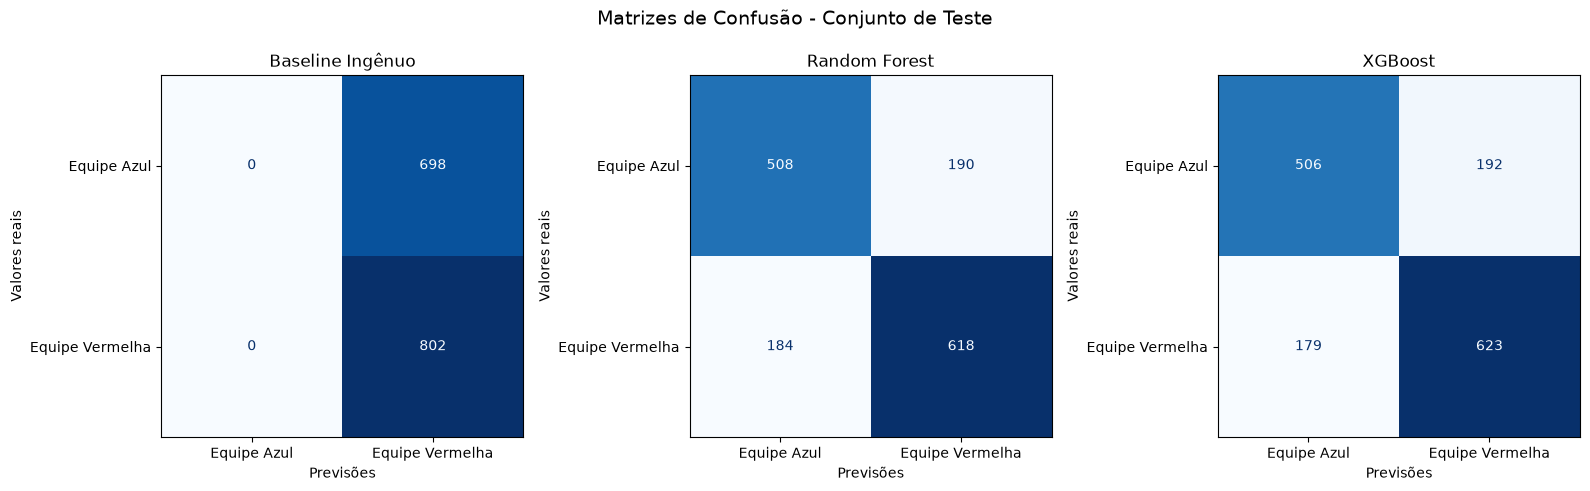

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Matrizes e respectivos nomes
matrizes = [
    ("Baseline Ingênuo", matriz_baseline),
    ("Random Forest", matriz_random_forest),
    ("XGBoost", matriz_xgboost)
]

# Criação da figura
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nome_modelo, matriz) in zip(axes, matrizes):

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Equipe Azul", "Equipe Vermelha"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(nome_modelo)
    ax.set_xlabel("Previsões")
    ax.set_ylabel("Valores reais")

plt.suptitle("Matrizes de Confusão - Conjunto de Teste", fontsize=14)
plt.tight_layout()
plt.show()

## Análise dos Modelos de Redes Neurais

Nesta etapa, serão analisados os resultados dos modelos CNN-1D, RNN, LSTM e GRU, arquiteturas de redes neurais utilizadas para identificar padrões e relações temporais presentes nas partidas de *League of Legends*.

Diferentemente dos modelos tradicionais apresentados anteriormente, essas arquiteturas possuem um processo de treinamento iterativo, permitindo acompanhar a evolução do aprendizado ao longo das épocas. Dessa forma, a análise será iniciada pelas **curvas de aprendizagem**, considerando as perdas (*loss*) de treinamento e validação, com o objetivo de observar a convergência dos modelos, possíveis sinais de *overfitting* e sua capacidade de generalização.

Em seguida, serão examinadas as **matrizes de confusão do conjunto de teste**, permitindo identificar a distribuição dos acertos e erros para cada equipe e verificar possíveis diferenças no desempenho da classificação entre as classes.

Por fim, será apresentada uma **tabela comparativa**, reunindo as métricas Accuracy, F1 Macro e Balanced Accuracy dos conjuntos de validação e teste. Essa comparação permitirá avaliar o desempenho das diferentes arquiteturas recorrentes e convolucionais, identificando quais apresentam resultados mais consistentes para o problema de classificação proposto.

In [9]:
# Curvas de aprendizagem - CNN-1D
curvas_cnn = {
    "epocas": [1, 2, 3, 4, 5, 6, 7],
    "loss_treino": [
        0.5215151906, 0.4856173694, 0.4747109413,
        0.4686034918, 0.4628601372, 0.457826822996,
        0.4522082508
    ],
    "loss_validacao": [
        0.4811587036, 0.4671817124, 0.4640325606,
        0.4630717039, 0.4657142758, 0.4684624076,
        0.4731737375
    ],
    "accuracy_treino": [
        0.7405714393, 0.7667142749, 0.7708571553,
        0.7735714316, 0.7768571377, 0.7789999843,
        0.7808571458
    ],
    "accuracy_validacao": [
        0.7673333287, 0.7786666751, 0.7820000052,
        0.7746666670, 0.7739999890, 0.7673333287,
        0.7673333287
    ]
}

# Curvas de aprendizagem - RNN
curvas_rnn = {
    "epocas": [1, 2, 3, 4, 5, 6, 7],
    "loss_treino": [
        0.5048525929, 0.4743171632, 0.4652867615,
        0.4526435435, 0.4406248033, 0.4314843118,
        0.4153576195
    ],
    "loss_validacao": [
        0.4856012464, 0.4808757007, 0.4765447974,
        0.4759320915, 0.4869416952, 0.4988261163,
        0.5056855679
    ],
    "accuracy_treino": [
        0.7549999952, 0.7712857127, 0.7758571506,
        0.7835714221, 0.7879999876, 0.7907142639,
        0.7977142930
    ],
    "accuracy_validacao": [
        0.7726666927, 0.7673333287, 0.7713333368,
        0.7653333545, 0.7659999728, 0.7540000081,
        0.7540000081
    ]
}

# Curvas de aprendizagem - LSTM
curvas_lstm = {
    "epocas": [1, 2, 3, 4, 5],
    "loss_treino": [
        0.5190371275, 0.4774026573, 0.4651203752,
        0.4566863477, 0.4477335811
    ],
    "loss_validacao": [
        0.4708014429, 0.4684331417, 0.4719181657,
        0.4727820754, 0.4731851816
    ],
    "accuracy_treino": [
        0.7471428514, 0.7699999809, 0.7742857337,
        0.7787142992, 0.7871428728
    ],
    "accuracy_validacao": [
        0.7773333192, 0.7739999890, 0.7766666412,
        0.7746666667, 0.7733333111
    ]
}

# Curvas de aprendizagem - GRU
curvas_gru = {
    "epocas": [1, 2, 3, 4, 5, 6, 7],
    "loss_treino": [
        0.5006133914, 0.4751856029, 0.4656442106,
        0.4567518234, 0.4475688934, 0.4370053113,
        0.4253452122
    ],
    "loss_validacao": [
        0.4737626910, 0.4696942866, 0.4677688777,
        0.4656477571, 0.4682421982, 0.4731405377,
        0.4857344031
    ],
    "accuracy_treino": [
        0.7552857399, 0.7715714574, 0.7765714526,
        0.7820000052, 0.7882857323, 0.7964285612,
        0.8014285564
    ],
    "accuracy_validacao": [
        0.7733333111, 0.7733333111, 0.7766666412,
        0.7706666589, 0.7633333206, 0.7639999986,
        0.7573333383
    ]
}

# Organização conjunta das curvas
curvas_modelos = {
    "CNN-1D": curvas_cnn,
    "RNN": curvas_rnn,
    "LSTM": curvas_lstm,
    "GRU": curvas_gru
}

print("Curvas de aprendizagem dos quatro modelos armazenadas com sucesso!")

Curvas de aprendizagem dos quatro modelos armazenadas com sucesso!


In [8]:
import numpy as np

# Matrizes de confusão - Conjunto de teste

matrizes_confusao = {
    "CNN-1D": np.array([
        [488, 210],
        [143, 659]
    ]),

    "RNN": np.array([
        [498, 200],
        [156, 646]
    ]),

    "LSTM": np.array([
        [488, 210],
        [142, 660]
    ]),

    "GRU": np.array([
        [478, 220],
        [138, 664]
    ])
}

print("Curvas de aprendizagem e matrizes de confusão armazenadas com sucesso!")

Curvas de aprendizagem e matrizes de confusão armazenadas com sucesso!


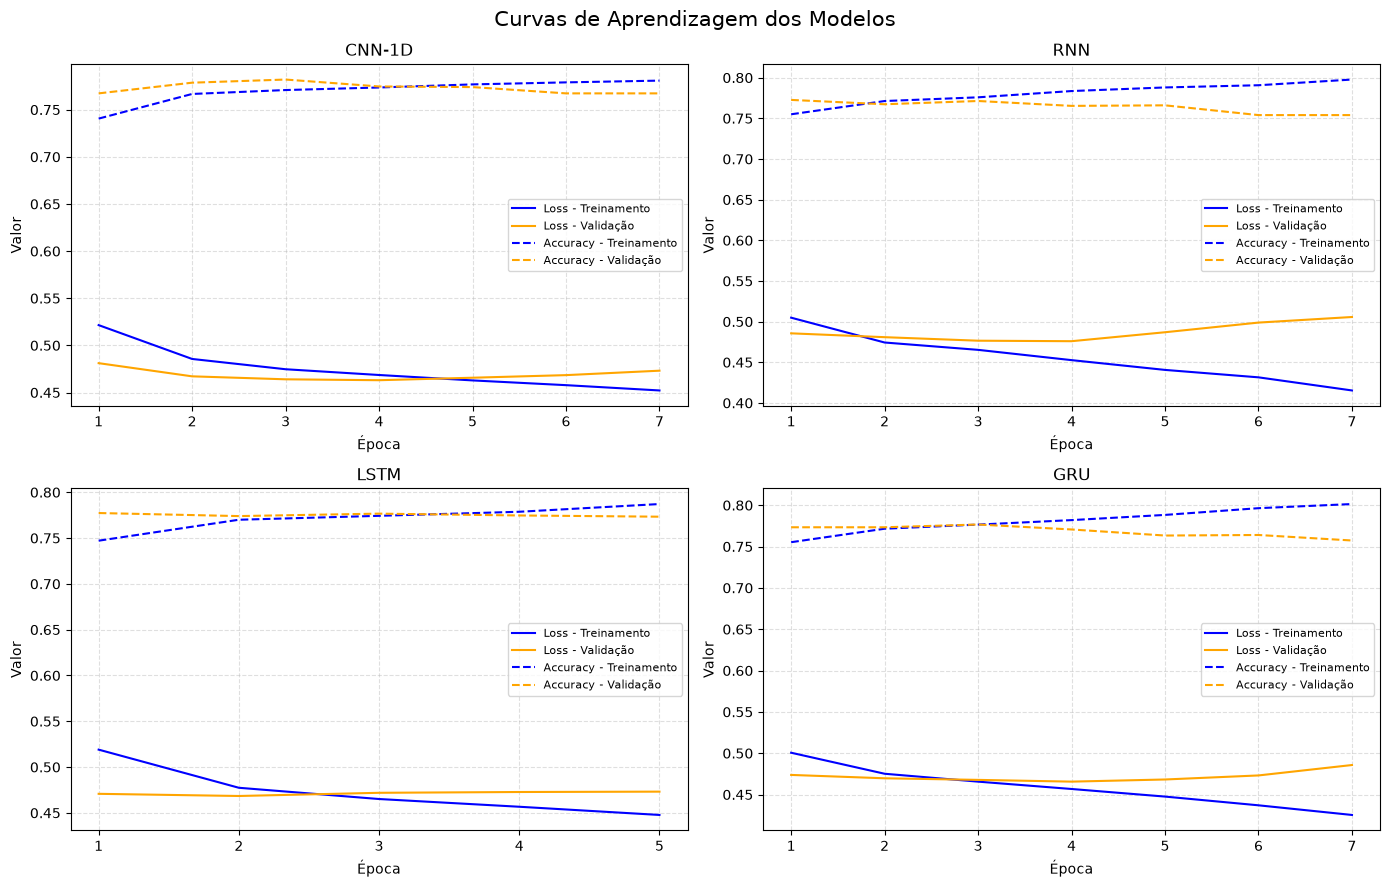

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

modelos = [
    ("CNN-1D", curvas_cnn, axes[0, 0]),
    ("RNN", curvas_rnn, axes[0, 1]),
    ("LSTM", curvas_lstm, axes[1, 0]),
    ("GRU", curvas_gru, axes[1, 1])
]

for nome, curvas, ax in modelos:

    epocas = curvas["epocas"]

    # Loss: linhas contínuas
    ax.plot(
        epocas,
        curvas["loss_treino"],
        color="blue",
        linestyle="-",
        label="Loss - Treinamento"
    )

    ax.plot(
        epocas,
        curvas["loss_validacao"],
        color="orange",
        linestyle="-",
        label="Loss - Validação"
    )

    # Accuracy: linhas tracejadas
    ax.plot(
        epocas,
        curvas["accuracy_treino"],
        color="blue",
        linestyle="--",
        label="Accuracy - Treinamento"
    )

    ax.plot(
        epocas,
        curvas["accuracy_validacao"],
        color="orange",
        linestyle="--",
        label="Accuracy - Validação"
    )

    ax.set_title(nome)
    ax.set_xlabel("Época")
    ax.set_ylabel("Valor")
    ax.set_xticks(epocas)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)

plt.suptitle("Curvas de Aprendizagem dos Modelos", fontsize=15)
plt.tight_layout()
plt.show()

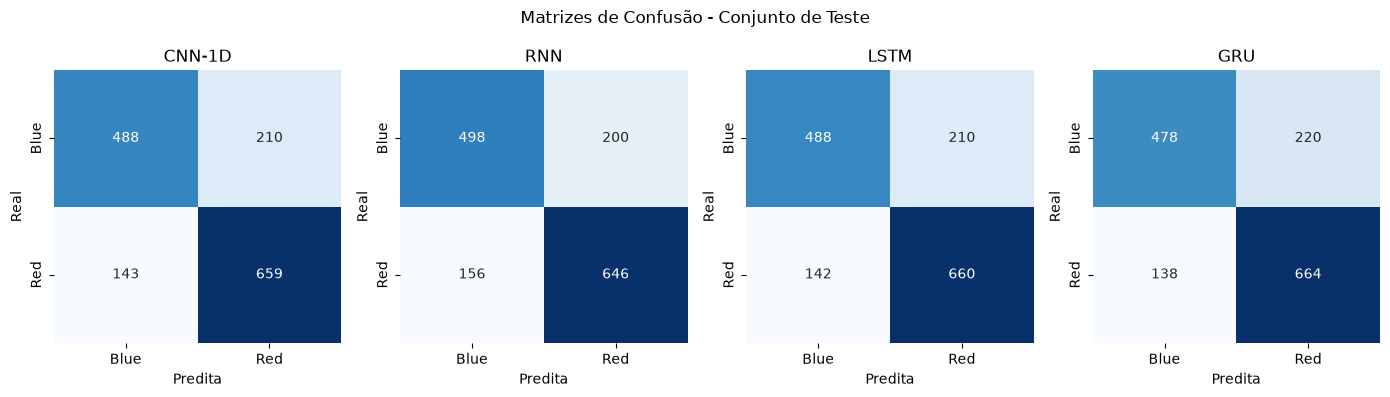

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

modelos = [
    ("CNN-1D", matrizes_confusao["CNN-1D"], axes[0]),
    ("RNN", matrizes_confusao["RNN"], axes[1]),
    ("LSTM", matrizes_confusao["LSTM"], axes[2]),
    ("GRU", matrizes_confusao["GRU"], axes[3])
]

classes = ["Blue", "Red"]

for nome, matriz, ax in modelos:

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=ax,
        cbar=False,
        annot_kws={"size": 10}
    )

    ax.set_title(nome)
    ax.set_xlabel("Predita")
    ax.set_ylabel("Real")

plt.suptitle("Matrizes de Confusão - Conjunto de Teste")
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

# Resultados da CNN-1D
resultados_cnn = {
    "validacao": {
        "Accuracy": 0.7747,
        "F1 Macro": 0.7694,
        "Balanced Accuracy": 0.7673
    },
    "teste": {
        "Accuracy": 0.7647,
        "F1 Macro": 0.7616,
        "Balanced Accuracy": 0.7604
    }
}

# Resultados da RNN
resultados_rnn = {
    "validacao": {
        "Accuracy": 0.7653,
        "F1 Macro": 0.7613,
        "Balanced Accuracy": 0.7598
    },
    "teste": {
        "Accuracy": 0.7627,
        "F1 Macro": 0.7603,
        "Balanced Accuracy": 0.7595
    }
}

# Resultados da LSTM
resultados_lstm = {
    "validacao": {
        "Accuracy": 0.7740,
        "F1 Macro": 0.7689,
        "Balanced Accuracy": 0.7668
    },
    "teste": {
        "Accuracy": 0.7653,
        "F1 Macro": 0.7622,
        "Balanced Accuracy": 0.7610
    }
}

# Resultados da GRU
resultados_gru = {
    "validacao": {
        "Accuracy": 0.7707,
        "F1 Macro": 0.7645,
        "Balanced Accuracy": 0.7622
    },
    "teste": {
        "Accuracy": 0.7613,
        "F1 Macro": 0.7576,
        "Balanced Accuracy": 0.7564
    }
}

# Agrupamento dos resultados dos quatro modelos
resultados_modelos = {
    "CNN-1D": resultados_cnn,
    "RNN": resultados_rnn,
    "LSTM": resultados_lstm,
    "GRU": resultados_gru
}

# Comparação dos modelos - Validação
df_validacao = pd.DataFrame({
    nome: resultados["validacao"]
    for nome, resultados in resultados_modelos.items()
}).T

print("COMPARAÇÃO DOS MODELOS - VALIDAÇÃO")
display(df_validacao.round(4))

# Comparação dos modelos - Teste
df_teste = pd.DataFrame({
    nome: resultados["teste"]
    for nome, resultados in resultados_modelos.items()
}).T

print("COMPARAÇÃO DOS MODELOS - TESTE")
display(df_teste.round(4))

# Mini-relatório comparativo
melhor_validacao = df_validacao["F1 Macro"].idxmax()
melhor_teste = df_teste["F1 Macro"].idxmax()

print("\nMINI-RELATÓRIO COMPARATIVO")
print("-" * 60)

print(
    f"Melhor modelo na validação: {melhor_validacao} "
    f"(F1 Macro: {df_validacao.loc[melhor_validacao, 'F1 Macro']:.4f})"
)

print(
    f"Melhor modelo no teste: {melhor_teste} "
    f"(F1 Macro: {df_teste.loc[melhor_teste, 'F1 Macro']:.4f})"
)

COMPARAÇÃO DOS MODELOS - VALIDAÇÃO


,Accuracy,F1 Macro,Balanced Accuracy
CNN-1D,0.7747,0.7694,0.7673
RNN,0.7653,0.7613,0.7598
LSTM,0.7740,0.7689,0.7668
GRU,0.7707,0.7645,0.7622


COMPARAÇÃO DOS MODELOS - TESTE


,Accuracy,F1 Macro,Balanced Accuracy
CNN-1D,0.7647,0.7616,0.7604
RNN,0.7627,0.7603,0.7595
LSTM,0.7653,0.7622,0.7610
GRU,0.7613,0.7576,0.7564



MINI-RELATÓRIO COMPARATIVO
------------------------------------------------------------
Melhor modelo na validação: CNN-1D (F1 Macro: 0.7694)
Melhor modelo no teste: LSTM (F1 Macro: 0.7622)


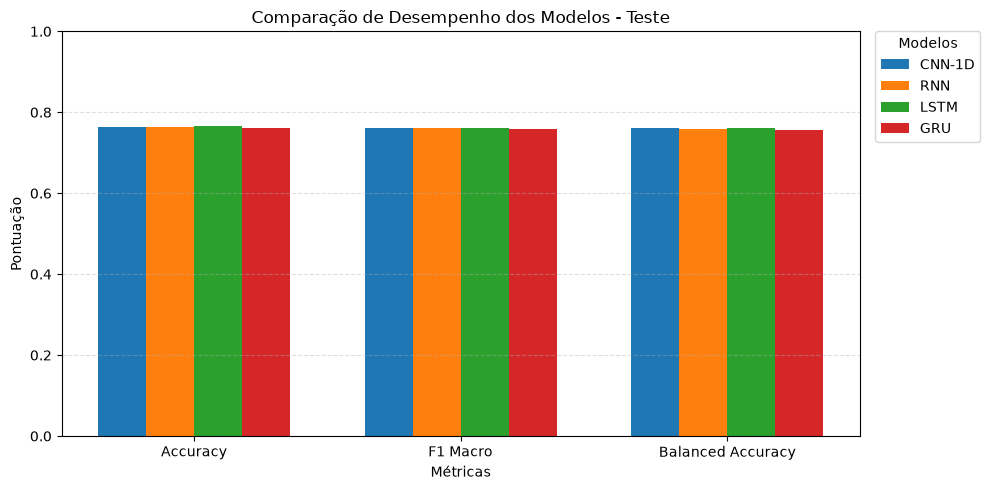

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Métricas
metricas = ["Accuracy", "F1 Macro", "Balanced Accuracy"]

# Modelos
modelos = df_teste.index.tolist()

x = np.arange(len(metricas))
largura = 0.18

plt.figure(figsize=(10, 5))

for i, modelo in enumerate(modelos):
    valores = df_teste.loc[modelo, metricas].values

    plt.bar(
        x + (i - (len(modelos) - 1) / 2) * largura,
        valores,
        largura,
        label=modelo
    )

plt.title("Comparação de Desempenho dos Modelos - Teste")
plt.ylabel("Pontuação")
plt.xlabel("Métricas")
plt.xticks(x, metricas)
plt.ylim(0, 1)

plt.legend(
    title="Modelos",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()